# 05 · Clustering: K-Means, estabilidad, benchmark y proyecciones

Entrena el modelo final (K-Means con *k* = 5), mide su **estabilidad** (el criterio principal de
calidad del proyecto), lo compara con un baseline por quintiles, GMM, Agglomerative (Ward) y
DBSCAN, y visualiza los segmentos con **PCA** y **t-SNE**.

- **Entrada:** `data/processed/lrfmc_scaled.parquet` y `lrfmc.parquet` (`uv run poe transform`).
- **Salidas** (`uv run poe cluster`): `segments.parquet`, `metrics.json`, `stability.csv`,
  `benchmark.csv` y `k_distance.csv` en `data/processed/`; `kmeans.joblib` y `gmm.joblib` en
  `models/`. Proyecciones (`uv run poe project`): `pca_variance.csv`, `pca_loadings.csv`,
  `pca_projection.parquet`, `tsne.parquet` y `projection.json`.
- Código: `src/segmentacion/models/{kmeans,baseline,benchmark}.py` y
  `src/segmentacion/projection/reduce.py`. Versión web: página **Clustering**.

In [1]:
import itertools
import json

import numpy as np
import pandas as pd
from IPython.display import HTML
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

from segmentacion.config import get_config
from segmentacion.features.lrfmc import LRFMC_COLUMNS
from segmentacion.models.baseline import BASELINE_SEGMENTS, baseline_segments, quintile_scores
from segmentacion.models.benchmark import fit_dbscan, run_benchmark
from segmentacion.models.k_selection import cluster_medians, stratified_sample
from segmentacion.models.kmeans import fit_kmeans, stability_ari, subsample_stability
from segmentacion.projection.reduce import pca_project, tsne_project
from segmentacion.viz import charts_3d
from segmentacion.viz import model_charts as mc
from segmentacion.viz import projection_charts as pc
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.float_format", "{:,.3f}".format)
config = get_config()
k, params, quality = config.k_selection.chosen_k, config.modeling, config.quality

features = pd.read_parquet(config.scaled_file)[list(LRFMC_COLUMNS)]
lrfmc = pd.read_parquet(config.lrfmc_file)
original = lrfmc[list(LRFMC_COLUMNS)]
print(f"{len(features):,} socios · k = {k}")

62,044 socios · k = 5


## 1. Modelo final

K-Means con 10 inicializaciones (`n_init=10`) y semilla fija, sobre el 100 % de los socios.

In [2]:
kmeans = fit_kmeans(features, k, config.random_state)
labels = kmeans.labels_
cluster_medians(original, labels).set_index("cluster")

,L,R,F,M,C,pct
cluster,,,,,,
0,23.589,1.933,11.000,"15,314.000",0.704,0.231
1,68.895,0.633,24.000,"34,336.500",0.741,0.213
2,28.945,8.733,3.000,"4,422.000",0.505,0.144
3,73.758,4.167,6.000,"9,131.000",0.700,0.217
4,31.704,11.467,3.000,"3,731.000",0.821,0.194


Son los mismos cinco grupos de la vista previa del notebook 04 (misma semilla): recientes y
activos (0), veteranos muy frecuentes (1), inactivos que compran barato (2), veteranos
ocasionales (3) e inactivos que pagan tarifa casi completa (4).

## 2. Estabilidad (criterio principal)

### 2.1 ¿Detecta el ARI un *k* equivocado?

Antes de medir los datos reales se comprueba con 4 grupos sintéticos que el ARI entre semillas
es alto con el *k* correcto y baja cuando se fuerzan grupos que no existen.

In [3]:
blobs, _ = make_blobs(n_samples=1_000, centers=4, n_features=5, random_state=7)
blobs = pd.DataFrame(blobs, columns=list(LRFMC_COLUMNS))
pd.DataFrame(
    {
        "k": [4, 7],
        "ari_medio": [stability_ari(blobs, kk, range(5))["ari"].mean() for kk in (4, 7)],
    }
).set_index("k")

,ari_medio
k,
4,1.000
7,0.764


### 2.2 Semillas y submuestras

- **Semillas:** 10 modelos con semillas distintas, comparados por pares (45 ARI).
- **Submuestras:** 10 modelos entrenados con el 80 % de los socios que asignan a **todos**; se
  comparan con el modelo completo.

In [4]:
seeds = stability_ari(features, k, range(params.stability_seeds))
subsamples = subsample_stability(
    features, k, params.subsample_runs, params.subsample_fraction, config.random_state
)
summary = pd.DataFrame(
    {
        "semillas": seeds["ari"].describe()[["count", "mean", "min", "max"]],
        "submuestras": subsamples["ari"].describe()[["count", "mean", "min", "max"]],
    }
).T
summary

,count,mean,min,max
semillas,45.000,0.980,0.964,0.998
submuestras,10.000,0.969,0.953,0.979


alt.LayerChart(...)
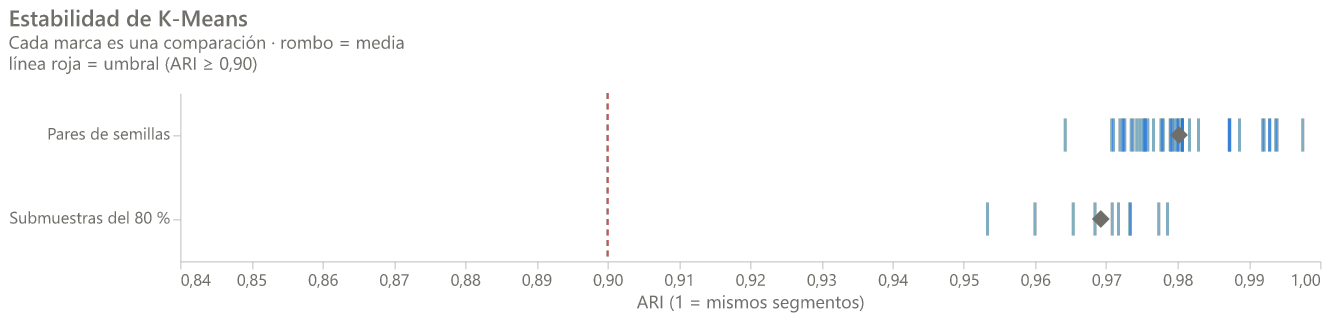

In [5]:
stability = pd.concat(
    [
        seeds.assign(
            method="semillas", run=seeds["seed_a"].astype(str) + "–" + seeds["seed_b"].astype(str)
        ),
        subsamples.assign(method="submuestras", run=subsamples["run"].astype(str)),
    ]
)[["method", "run", "ari"]]
mc.stability_chart(stability, quality.min_stability_ari)

Las 55 comparaciones superan el umbral de 0,90 con holgura: los segmentos no dependen de la
semilla ni de qué socios se usan para entrenar.

### 2.3 Comprobaciones adicionales

**¿Importan las 10 inicializaciones?** Con `n_init=1` cada semilla parte de una única
inicialización y puede quedarse en un mínimo local peor.

In [6]:
single = [KMeans(k, n_init=1, random_state=s).fit(features).labels_ for s in range(10)]
single_ari = [adjusted_rand_score(a, b) for a, b in itertools.combinations(single, 2)]
print(f"n_init = 1:  ARI medio {np.mean(single_ari):.3f} (mín. {np.min(single_ari):.3f})")
print(f"n_init = 10: ARI medio {seeds['ari'].mean():.3f} (mín. {seeds['ari'].min():.3f})")

n_init = 1:  ARI medio 0.942 (mín. 0.890)
n_init = 10: ARI medio 0.980 (mín. 0.964)


Con una sola inicialización algún par de semillas cae por debajo de 0,90: las 10
inicializaciones son parte de lo que hace estable al modelo.

**¿Es *k* = 5 menos estable que sus vecinos?**

In [7]:
pd.DataFrame(
    [
        {"k": kk, **stability_ari(features, kk, range(10))["ari"].agg(["mean", "min"])}
        for kk in (3, 4, 5, 6, 7)
    ]
).set_index("k")

,mean,min
k,,
3,0.972,0.931
4,0.987,0.974
5,0.980,0.964
6,0.979,0.962
7,0.983,0.939


Todos los *k* entre 3 y 7 son estables (ARI medio ≥ 0,97), así que la estabilidad no sirve
para elegir *k* (esa decisión se tomó en el notebook 04), pero confirma que *k* = 5 no paga
ningún costo en estabilidad.

## 3. Baseline por quintiles

Cada métrica se puntúa de 1 a 5 según su quintil (R invertida: menos meses sin volar = 5). Los
segmentos salen de reglas RFM clásicas sobre R y el valor FM (media de F y M):

| Segmento | Regla |
|---|---|
| Campeones | R ≥ 4 y FM ≥ 4 |
| Leales | FM ≥ 4 |
| En riesgo | R ≤ 2 y FM ≥ 3 |
| Hibernando | R ≤ 2 |
| Potenciales | el resto |

In [8]:
scores = quintile_scores(original)
baseline = baseline_segments(scores)
scores.apply(pd.Series.value_counts)

,L,R,F,M,C
1,12394,12425,9806,12408,12408
2,12416,12444,16024,12397,12409
3,12410,12325,11785,12420,12409
4,12423,12362,11890,12409,12409
5,12401,12488,12539,12410,12409


Los empates (por ejemplo, los muchos socios con 2 o 3 vuelos) reciben la misma puntuación, por
eso F no tiene exactamente un 20 % en cada quintil.

In [9]:
table = original.groupby(baseline).median()
table["pct"] = baseline.value_counts(normalize=True)
table.loc[list(BASELINE_SEGMENTS)]

,L,R,F,M,C,pct
baseline_segment,,,,,,
Campeones,50.727,0.567,20.000,"27,993.000",0.724,0.272
Leales,45.700,4.467,13.000,"19,231.000",0.717,0.164
En riesgo,38.505,9.333,6.000,"9,205.000",0.707,0.094
Hibernando,35.187,12.567,3.000,"3,757.000",0.710,0.236
Potenciales,40.345,2.000,5.000,"6,368.500",0.690,0.234


El descuento típico (C ≈ 0,70) es el mismo en los cinco segmentos: las reglas no ven la
sensibilidad al precio.

## 4. Benchmark

In [10]:
bench = run_benchmark(
    features,
    labels,
    baseline.to_numpy(),
    k,
    covariance_types=params.gmm_covariance_types,
    gmm_n_init=params.gmm_n_init,
    agglomerative_sample_size=params.agglomerative_sample_size,
    dbscan_min_samples=params.dbscan_min_samples,
    silhouette_sample_size=params.silhouette_sample_size,
    random_state=config.random_state,
)
bench.table.set_index("model")

,n_clusters,noise_pct,silhouette,db,min_cluster_pct,max_cluster_pct,ari_kmeans,seconds
model,,,,,,,,
K-Means,5,0.000,0.211,1.362,0.144,0.231,1.000,NaN
Quintiles LRFMC,5,0.000,0.109,2.078,0.094,0.272,0.268,NaN
GMM,5,0.000,0.118,2.326,0.152,0.260,0.396,6.739
Agglomerative (Ward),5,0.000,0.140,1.445,0.134,0.276,0.569,2.791
DBSCAN,1,0.012,NaN,NaN,0.988,0.988,0.000,6.577


El tiempo de K-Means no se midió aquí (el pipeline lo registra en `benchmark.csv`).

- **K-Means** tiene el mejor silhouette y Davies-Bouldin. Ojo: ambas métricas premian grupos
  compactos en distancia euclídea, que es lo que optimiza K-Means.
- **Ward** es el más parecido a K-Means (ARI ≈ 0,57).
- **GMM** y el **baseline** coinciden poco con K-Means y separan peor.
- **DBSCAN** no encuentra grupos: un único grupo denso + ruido.

alt.Chart(...)
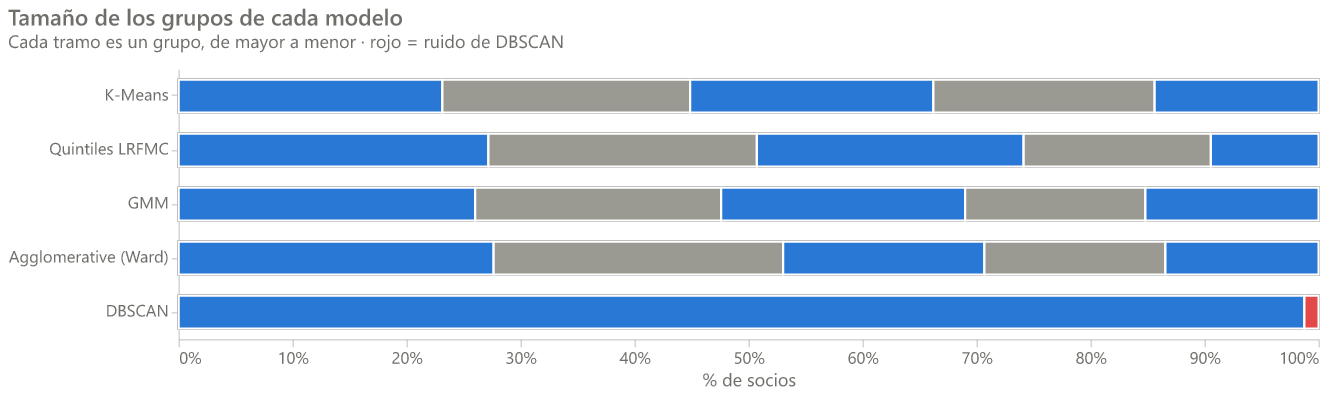

In [11]:
segments = pd.DataFrame(
    {
        "cluster": labels,
        "baseline_segment": baseline.to_numpy(),
        "gmm_cluster": bench.labels["GMM"],
        "gmm_proba": bench.gmm.predict_proba(features).max(axis=1),
        "agglomerative_cluster": bench.labels["Agglomerative (Ward)"],
        "dbscan_outlier": bench.labels["DBSCAN"] == -1,
    }
)
mc.model_sizes_chart(segments)

### 4.1 K-Means frente al baseline

alt.LayerChart(...)
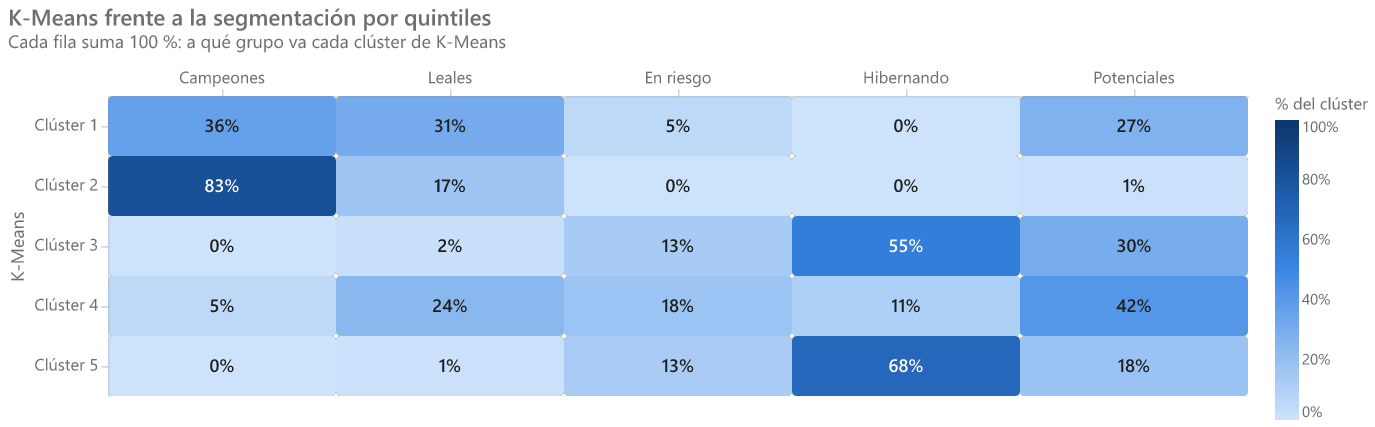

In [12]:
mc.crosstab_chart(segments, "baseline_segment", "K-Means frente a la segmentación por quintiles")

Los dos grupos inactivos de K-Means (clústeres 3 y 5 en el gráfico) caen mayoritariamente en
«Hibernando»: el baseline los trata igual aunque uno compra con mucho descuento y el otro paga
casi la tarifa completa. Los veteranos ocasionales (clúster 4) se reparten entre Potenciales,
Leales y En riesgo.

### 4.2 GMM: covarianza y probabilidad de pertenencia

In [13]:
bench.gmm_bic.set_index("covariance_type")

,bic
covariance_type,
full,"709,493.512"
diag,"642,923.526"


In [14]:
segments["gmm_proba"].describe(percentiles=[0.05, 0.25, 0.5])

count   62,044.000
mean         0.918
std          0.134
min          0.346
5%           0.586
25%          0.897
50%          0.991
max          1.000
Name: gmm_proba, dtype: float64

alt.LayerChart(...)
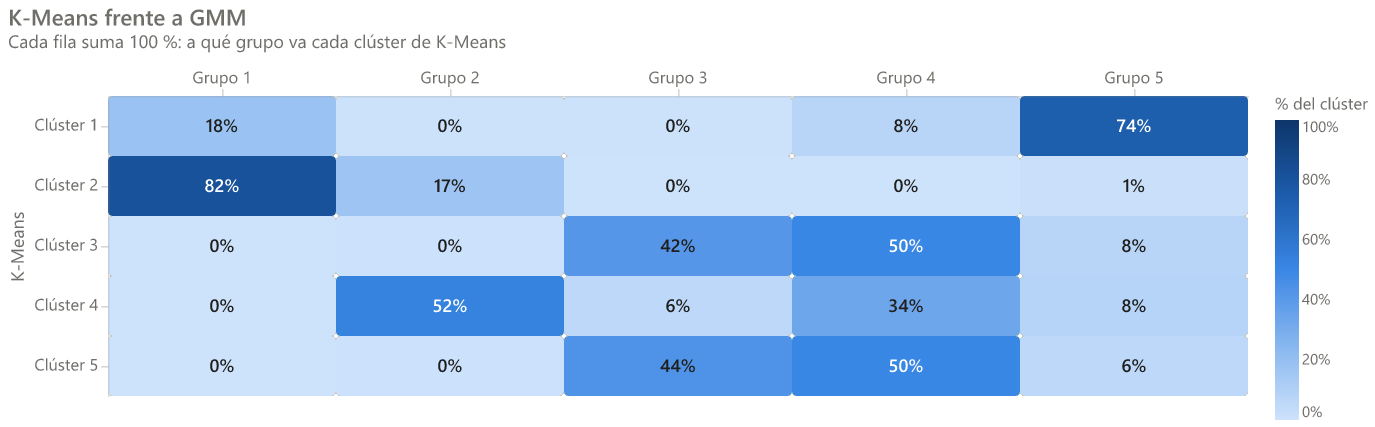

In [15]:
mc.crosstab_chart(segments, "gmm_cluster", "K-Means frente a GMM")

La covarianza diagonal tiene menor BIC. GMM conserva el núcleo de veteranos muy frecuentes, pero
mezcla a los dos grupos inactivos. Una cuarta parte de los socios tiene menos de un 90 % de
probabilidad de pertenecer a su componente: los grupos se solapan.

### 4.3 DBSCAN y socios atípicos

eps elegido (codo de k-distance): 0.616


alt.LayerChart(...)
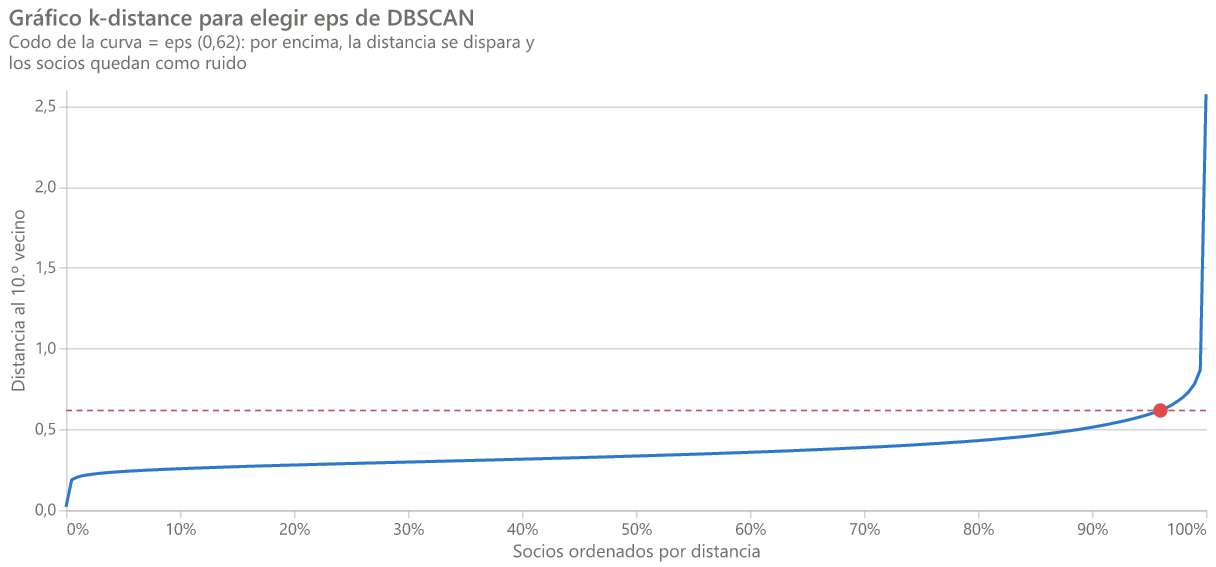

In [16]:
print(f"eps elegido (codo de k-distance): {bench.eps:.3f}")
mc.k_distance_chart(bench.k_distance, bench.eps, params.dbscan_min_samples)

**Sensibilidad a `eps`:** con un `eps` menor DBSCAN no descubre segmentos, solo fragmenta la
nube en un grupo grande y una docena de grupos diminutos; con uno mayor casi todo es un único grupo.

In [17]:
rows = []
for eps in (0.5, bench.eps, 0.75):
    dbscan = fit_dbscan(features, eps, params.dbscan_min_samples)
    sizes = np.bincount(dbscan[dbscan >= 0]) / len(dbscan)
    rows.append(
        {
            "eps": eps,
            "grupos": len(sizes),
            "ruido": (dbscan == -1).mean(),
            "grupo_mayor": sizes.max(),
        }
    )
pd.DataFrame(rows).set_index("eps")

,grupos,ruido,grupo_mayor
eps,,,
0.500,14,0.050,0.947
0.616,1,0.012,0.988
0.750,1,0.003,0.997


In [18]:
outlier = segments["dbscan_outlier"].to_numpy()
profile = original.groupby(np.where(outlier, "atípicos", "resto")).median()
profile["C > 1"] = (original["C"] > 1).groupby(np.where(outlier, "atípicos", "resto")).mean()
profile

,L,R,F,M,C,C > 1
atípicos,39.064,2.633,4.000,"19,422.000",0.908,0.406
resto,42.021,3.500,7.000,"10,166.000",0.712,0.043


Los atípicos (≈ 1,2 %) vuelan poco pero muy lejos y muchos pagan más que la tarifa completa
(cabinas premium). No son un segmento, pero conviene revisarlos antes de campañas masivas.

## 5. Reducción de dimensionalidad (visualización)

Las proyecciones solo sirven para **ver** los segmentos; K-Means se entrenó con las cinco
features y aquí no se vuelve a agrupar.

### 5.1 PCA

In [19]:
pca = pca_project(features, n=3)
pca.explained.set_index("component")

,variance,cumulative
component,,
PC1,0.486,0.486
PC2,0.203,0.689
PC3,0.182,0.871
PC4,0.108,0.979
PC5,0.021,1.000


alt.LayerChart(...)
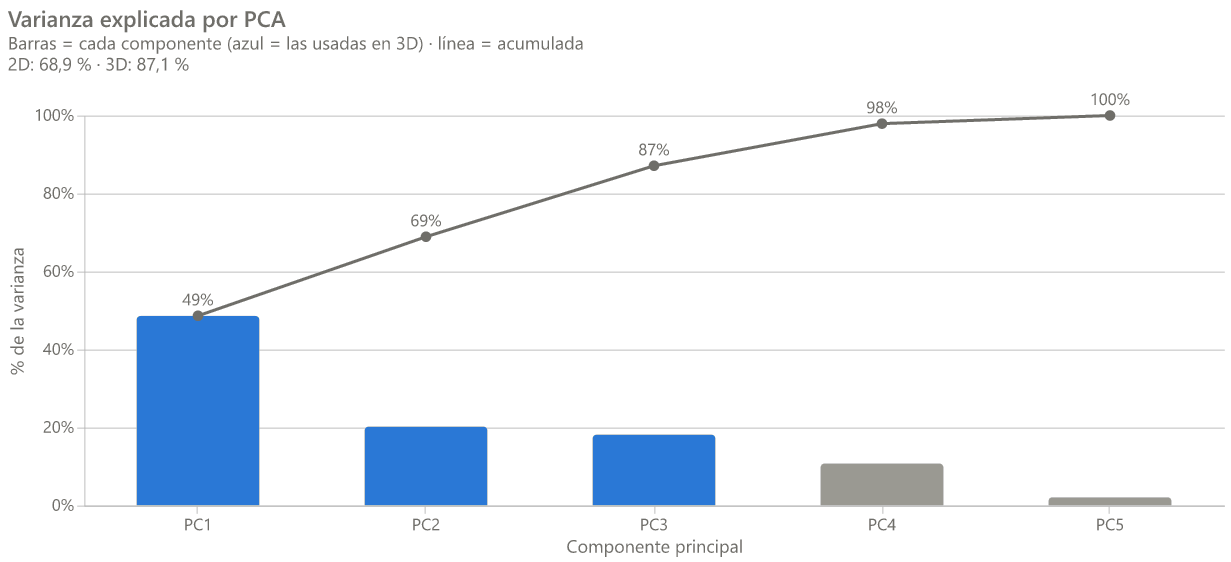

In [20]:
pc.pca_variance_chart(pca.explained)

In [21]:
pca.loadings.round(2)

,L,R,F,M,C
PC1,0.200,-0.480,0.600,0.590,0.140
PC2,0.540,0.200,-0.070,-0.130,0.800
PC3,0.810,0.020,-0.080,-0.040,-0.570


- **PC1 (≈ 49 %) = actividad:** F y M positivos, R negativo.
- **PC2 (≈ 20 %) = precio y antigüedad:** sobre todo C (+0,80) y L (+0,54).
- **PC3 (≈ 18 %) = antigüedad frente a precio:** L (+0,81) frente a C (−0,57).

PC2 y PC3 explican casi lo mismo, así que el plano 2D (69 %) deja fuera una dimensión
importante; con 3D se llega al 87 %.

**¿Dónde cae cada clúster?** Mediana de cada componente por clúster (todos los socios):

In [22]:
pca.scores.groupby(labels).median().rename_axis("cluster").round(2)

,PC1,PC2,PC3
cluster,,,
0,0.520,-0.650,-0.790
1,2.030,0.130,0.330
2,-1.690,-1.000,0.400
3,-0.030,0.510,0.770
4,-1.640,0.670,-0.620


PC1 ordena de inactivos (clústeres 2 y 4 en numeración 0-based) a muy frecuentes (1); PC2
separa a los dos inactivos por el precio (4 arriba, 2 abajo) y PC3 separa a los recientes (0)
de los veteranos ocasionales (3).

alt.LayerChart(...)
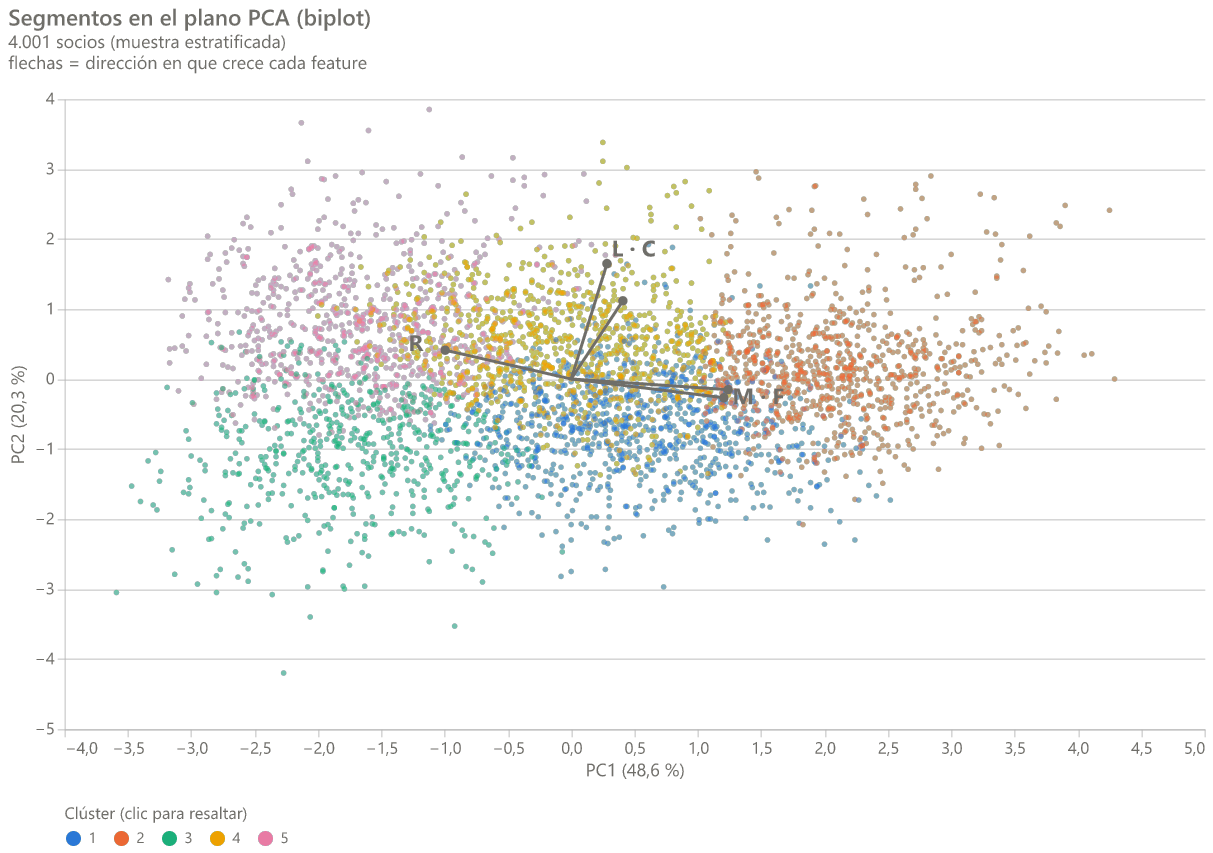

In [23]:
pca_sample = stratified_sample(labels, config.projection.pca_sample_size, config.random_state)
points = pca.scores.iloc[pca_sample].assign(cluster=labels[pca_sample])
pc.pca_scatter_chart(points, pca.loadings, pca.explained)

PCA 3D (Plotly, rotable). Es interactivo en JupyterLab / VS Code; GitHub no muestra gráficos
Plotly, la versión web está en la página **Clustering**.

In [24]:
HTML(charts_3d.figure_html(charts_3d.pca_3d_figure(points, pca.explained)))

### 5.2 t-SNE

Se lee el t-SNE calculado por el pipeline (8.000 socios, perplexity 30 y 50; ~50 s). Antes se
comprueban dos requisitos: que la muestra está **estratificada por clúster** y que el resultado
es **reproducible** con semilla fija.

In [25]:
tsne = pd.read_parquet(config.tsne_file)
sample_share = tsne.drop_duplicates("MEMBER_NO")["cluster"].value_counts(normalize=True)
pd.DataFrame(
    {
        "muestra_tsne": sample_share.sort_index(),
        "población": pd.Series(labels).value_counts(normalize=True).sort_index(),
    }
)

,muestra_tsne,población
0,0.231,0.231
1,0.213,0.213
2,0.144,0.144
3,0.217,0.217
4,0.194,0.194


In [26]:
check = stratified_sample(labels, 1_000, random_state=0)
first = tsne_project(features, check, perplexity=30, random_state=config.random_state)
second = tsne_project(features, check, perplexity=30, random_state=config.random_state)
print("Mismo resultado con la misma semilla:", first.equals(second))

Mismo resultado con la misma semilla: True


alt.Chart(...)
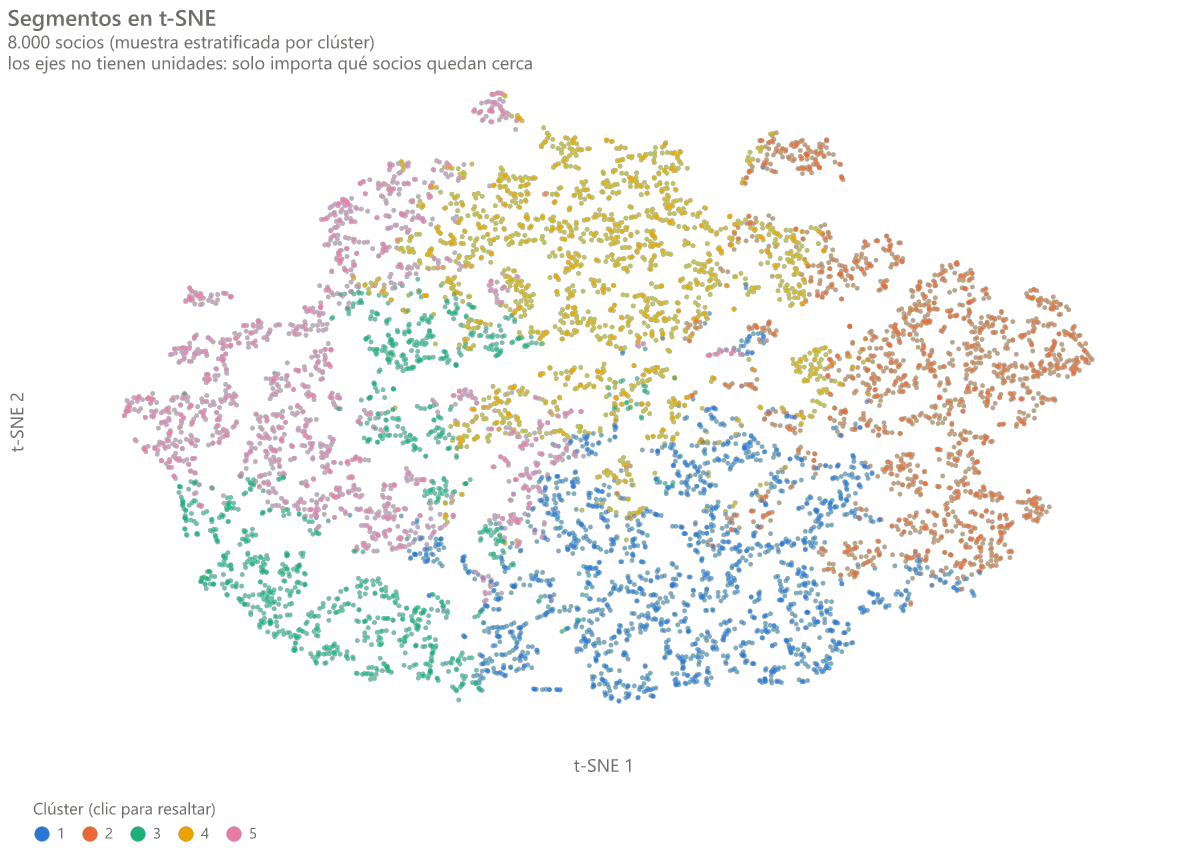

In [27]:
pc.tsne_chart(tsne, default_perplexity=30)

Cada clúster ocupa una región compacta, con fronteras de contacto pero sin mezclarse, y el
patrón se mantiene con ambas perplexities.

### 5.3 ¿Cuánto respeta cada proyección a los vecinos?

*Trustworthiness* (0–1): proporción de vecindarios del espacio LRFMC que se conservan en la
proyección. Calculado por el pipeline sobre 2.000 socios de la muestra de t-SNE.

In [28]:
projection = json.loads(config.projection_metrics_file.read_text(encoding="utf-8"))
pd.Series(projection["trustworthiness"], name="trustworthiness").to_frame()

,trustworthiness
PCA 2D,0.866
PCA 3D,0.954
t-SNE (perplexity 30),0.987
t-SNE (perplexity 50),0.987


t-SNE conserva casi todos los vecindarios (≈ 0,99) frente a ≈ 0,87 del plano PCA y ≈ 0,95 en
3D: PCA explica **qué ejes** separan a los segmentos y t-SNE muestra **quién está cerca de
quién**.

## Conclusiones

- **Estabilidad (criterio principal):** ARI medio entre semillas ≈ 0,98 y con submuestras del
  80 % ≈ 0,97, muy por encima de 0,90. Las 10 inicializaciones contribuyen: con una sola el ARI
  mínimo baja de 0,90.
- **Criterios secundarios:** silhouette 0,21 (≥ 0,20) y clúster mínimo del 14,4 % (≥ 3 %).
- **Benchmark:** K-Means separa mejor que el baseline, GMM, Ward y DBSCAN, con grupos
  equilibrados. El baseline por quintiles no ve la sensibilidad al precio; DBSCAN confirma que
  los clientes forman un continuo y aporta la marca de atípico; GMM aporta la probabilidad de
  pertenencia.
- **Proyecciones:** PCA explica el 69 % de la varianza en 2D y el 87 % en 3D, con ejes de
  negocio claros (actividad, precio, antigüedad); t-SNE (reproducible, muestra estratificada)
  muestra cada clúster como una región compacta y conserva el 99 % de los vecindarios.
- **Decisión:** K-Means con *k* = 5. Siguiente paso: perfilado, nombres y recomendaciones de
  los segmentos (notebook 06).